# Questions about building the AR4 arm

A person building the AR4 robot arm works from a 377-page manual. At each assembly step they look at a bench photo and its printed instruction and ask what the step needs: how many screws and which kind, which part goes in, which tool. On the parts-list pages they ask for facts, such as how many of one screw the whole robot needs. Each question is answered by reading an image and a sentence together, which is the input a vision-language model (VLM) takes.

In this assignment you measure how well [SmolVLM-256M-Instruct](https://arxiv.org/abs/2504.05299) answers these questions without training. You then fine-tune it in three ways and compare them. [LoRA](https://arxiv.org/abs/2106.09685) adds trainable low-rank matrices beside frozen attention and MLP weights. [DoRA](https://arxiv.org/abs/2402.09353) splits each of those weights into a magnitude and a direction and applies the low-rank update to the direction only. [LayerNorm tuning](https://arxiv.org/abs/2312.11420) trains nothing but the scale of the normalization layers. The first two train about three million parameters, the third about thirty-five thousand, out of 256 million.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Removing torchao due to Google Colab environment weirdness

In [ ]:
%pip install -q -U "transformers>=5" peft pymupdf datasets
%pip uninstall -y torchao

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
import hashlib
import inspect
import json
import marshal
import re
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf
import torch
from datasets import load_dataset
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from transformers.utils import logging as hf_logging

hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore", message="Unsupported layer type")  # RMSNorm under LayerNorm tuning

## Settings

Keep these values for the runs you hand in. `TRAIN_LIMIT` and `TEST_LIMIT` are there so that you can check your code on a few pairs first.

In [3]:
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
DATASET_ID = "aegean-ai/ar4-assembly-vqa"
MANUAL_URL = "https://raw.githubusercontent.com/Annin-Robotics/downloads/main/2026/02/AR4-MK4-Robot-Manul-1.1.pdf"
MANUAL_SHA256 = "44d5d8d60a94078f28744d449008dd5a80ef52ce46a400607ebb02d3eb8a7fd1"
EPOCHS = 2  # passes over the training pairs, every method
LR = 2e-4  # AdamW learning rate, every method
ACCUM = 4  # pairs per optimizer step
IMAGE_EDGE = 512  # longest image side kept by the processor, in pixels
TRAIN_LIMIT = None  # None trains on every pair
TEST_LIMIT = None  # None scores every test pair
SETTINGS = {"dataset": DATASET_ID, "epochs": EPOCHS, "lr": LR, "accum": ACCUM, "image_edge": IMAGE_EDGE,
            "train_limit": TRAIN_LIMIT, "test_limit": TEST_LIMIT}  # a saved run is reused only under these and unchanged method code
RUNS = Path("runs")  # one CSV and one JSON per method
DEVICE = "cuda"
RUNS.mkdir(exist_ok=True)

## The manual and its images

Each row of the dataset names a page of the manual and a box on that page, in PDF points (1/72 inch). The image for a question is that box, rendered at 110 dots per inch. A step box covers a whole panel: the bench photo on the left and the printed instruction on the right. The answer to a step question is therefore printed inside its image, and the model has to find it there and tie it to what the photo shows. Documentation boxes cover a grid of labeled part photos or the fastener table.

The boxes were measured on version 1.1 of the manual. A later revision moves things around on its pages, so the download is checked against the SHA-256 digest of version 1.1 before any box is cut.

In [4]:
MANUAL = Path("AR4-MK4-Robot-Manul-1.1.pdf")
if not MANUAL.exists():
    urllib.request.urlretrieve(MANUAL_URL, MANUAL)
digest = hashlib.sha256(MANUAL.read_bytes()).hexdigest()
assert digest == MANUAL_SHA256, f"{MANUAL} is not version 1.1 of the manual (sha256 {digest})"
manual = pymupdf.open(MANUAL)
_images = {}


def render(page, bbox):
    # The image a dataset row refers to: its box on its page, at 110 dpi.
    key = (int(page), tuple(float(v) for v in bbox))
    if key not in _images:
        pix = manual[key[0] - 1].get_pixmap(clip=pymupdf.Rect(*key[1]), dpi=110)
        _images[key] = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
    return _images[key]


print(f"{manual.page_count} pages, digest matches version 1.1")

377 pages, digest matches version 1.1


## The question-answer pairs

Step questions (`kind` is `step`) come from the assembly chapter, pages 51 to 241. They ask for a fastener count or type, the part installed, a tool or material, a specification such as a wire length, an action, or the joint a step belongs to. Documentation questions (`kind` is `doc`) come from the parts list, pages 16 to 50. They ask what a photo in a grid is called, where a part sits in the grid, or how many of a fastener the whole robot needs.

Consecutive assembly steps reuse nearly the same photo, so a random split would put near-copies of test images into training. The split is by page instead. The assembly pages are cut into blocks of ten and every fifth block is held out for test. Training pages right beside a test block are dropped, and so are training pairs whose panel contains a photo that also appears in a test panel.

In [5]:
data = load_dataset(DATASET_ID)
train_df = data["train"].to_pandas()
test_df = data["test"].to_pandas()
if TRAIN_LIMIT:
    train_df = train_df.sample(TRAIN_LIMIT, random_state=0)
if TEST_LIMIT:
    test_df = test_df.sample(TEST_LIMIT, random_state=0)
print(f"{len(train_df)} training pairs, {len(test_df)} test pairs")
pairs = pd.concat([train_df.assign(split="train"), test_df.assign(split="test")])
pd.crosstab(pairs.qtype, [pairs.split, pairs.kind])

Generating train split:   0%|          | 0/1149 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/344 [00:00<?, ? examples/s]

1149 training pairs, 344 test pairs


split          test      train     
kind            doc step   doc step
qtype                              
action            2   53     2  185
count             2   37    14   95
fastener          0   20     0   52
fastener_count    0   21     0   53
fastener_list     0   19     0   49
joint             2   14     7   33
name             12    0    22    0
part              2   43     8  159
spec             10   63    40  258
table_count       9    0    25    0
tool              1   27     0  129
where             7    0    18    0

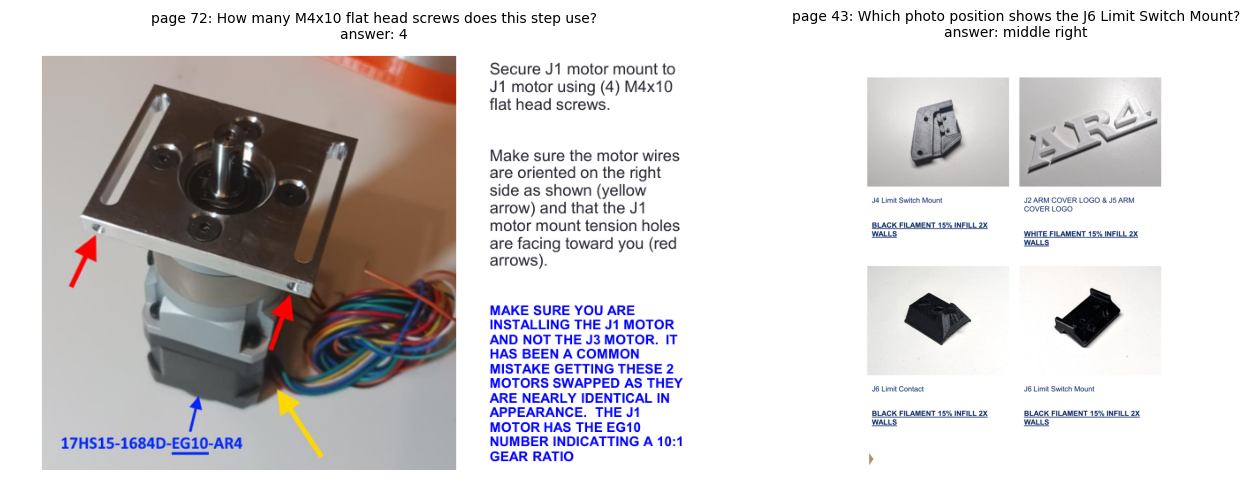

In [6]:
full_test = data["test"].to_pandas()
examples = [full_test[full_test.kind == "step"].iloc[0], full_test[full_test.qtype == "where"].iloc[0]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, row in zip(axes, examples):
    ax.imshow(render(row.page, row.bbox))
    ax.set_title(f"page {row.page}: {row.question}\nanswer: {row.answer}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Scoring answers

The answers are short: a count, a part name, a size. A model that says "toward the rear" when the reference says "toward rear" has the content right, but a plain string comparison marks it wrong. The graded score is therefore the normalized match. Both strings are lowercased, × becomes x, punctuation and brackets are removed, a number written with a leading decimal point gets a leading zero (so .375 and 0.375 match), the articles a, an and the are dropped, and the words that are left must be the same. Exact match, where the two strings are equal once surrounding spaces are trimmed, is reported beside it. The difference between the two tells you how much of a score comes from wording rather than content.

In [7]:
ARTICLES = {"a", "an", "the"}


def normalize(text):
    # Lowercase, x for ×, words and numbers only (decimals kept, .375 read as 0.375), articles dropped.
    words = re.findall(r"(?<![a-z0-9#.])\.\d+|[a-z0-9#]+(?:\.\d+)*", str(text).lower().replace("×", "x"))
    return " ".join("0" + w if w.startswith(".") else w for w in words if w not in ARTICLES)


def exact_match(pred, answer):
    return str(pred).strip() == str(answer).strip()


def normalized_match(pred, answer):
    return normalize(pred) == normalize(answer)


for pred, answer in [("toward the rear", "toward rear"), ("(1)", "1"), ("Terminal 20.", "20"), ("#6 x .375", "#6 X .375"), ("#6 x 0.375", "#6 x .375"), ("#6 x 375", "#6 x .375")]:
    print(f"{pred!r:20} {answer!r:14} exact {exact_match(pred, answer)!s:5}  normalized {normalized_match(pred, answer)}")

'toward the rear'    'toward rear'  exact False  normalized True
'(1)'                '1'            exact False  normalized True
'Terminal 20.'       '20'           exact False  normalized False
'#6 x .375'          '#6 X .375'    exact False  normalized True
'#6 x 0.375'         '#6 x .375'    exact False  normalized True
'#6 x 375'           '#6 x .375'    exact False  normalized False


## The model

SmolVLM-256M-Instruct joins a small image encoder to the SmolLM2 language model through a connector that turns image patches into tokens. Each image is resized so that its longer side is 512 pixels and read as a single tile. The question goes in as a chat turn with the image placed before the text, and the answer is generated greedily, at most 24 tokens long.

`evaluate` runs the model on a set of pairs and returns one row per pair, with the prediction and both scores.

In [8]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.image_processor.size = {"longest_edge": IMAGE_EDGE}


def load_model(dtype=torch.float32):
    return AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=dtype).to(DEVICE)


def chat(question, answer=None):
    # One user turn (image, then question), and the reference answer as the assistant turn when training.
    turns = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question + " Answer briefly."}]}]
    if answer is not None:
        turns.append({"role": "assistant", "content": [{"type": "text", "text": answer}]})
    return turns


@torch.no_grad()
def evaluate(model, df, max_new_tokens=24):
    model.eval()
    rows = []
    for r in df.itertuples():
        prompt = processor.apply_chat_template(chat(r.question), add_generation_prompt=True)
        x = processor(text=prompt, images=[render(r.page, r.bbox)], return_tensors="pt").to(DEVICE)
        x["pixel_values"] = x["pixel_values"].to(model.dtype)
        with torch.autocast("cuda", dtype=torch.float16):
            y = model.generate(**x, max_new_tokens=max_new_tokens, do_sample=False)
        pred = processor.batch_decode(y[:, x["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
        rows.append({"id": r.id, "kind": r.kind, "qtype": r.qtype, "question": r.question,
                     "answer": r.answer, "pred": pred})
    return score(pd.DataFrame(rows))


def score(out):
    out["exact"] = [exact_match(p, a) for p, a in zip(out.pred, out.answer)]
    out["normalized"] = [normalized_match(p, a) for p, a in zip(out.pred, out.answer)]
    return out


def fingerprint(configure):
    # Identifies a method's code: the source of its configure function and the plain values it reads, such as TARGETS.
    if configure is None:
        return None  # zero-shot trains nothing
    try:
        code = inspect.getsource(configure)
    except (OSError, TypeError):
        code = marshal.dumps(configure.__code__).hex()  # the compiled function when its source is not available
    values = {n: repr(v) for n in configure.__code__.co_names
              if isinstance(v := configure.__globals__.get(n), (str, int, float, list, tuple, dict))}
    return hashlib.sha256((code + json.dumps(values, sort_keys=True)).encode()).hexdigest()


def is_saved(name, code=None):
    # A saved run counts only when it was made with the current SETTINGS and the same method code.
    meta = RUNS / f"{name}.json"
    if not ((RUNS / f"{name}.csv").exists() and meta.exists()):
        return False
    saved = json.loads(meta.read_text())
    return saved.get("settings") == SETTINGS and saved.get("code") == code


def load_run(name):
    # The saved predictions, scored again with the current metric.
    return score(pd.read_csv(RUNS / f"{name}.csv", dtype={"answer": str, "pred": str}, keep_default_na=False))

## Part 1: the zero-shot baseline (20 points)

The base model answers every test question before any training. Its results are saved as `runs/zeroshot.csv` so that Part 3 can compare it with the fine-tuned models.

In [9]:
ZEROSHOT = RUNS / "zeroshot.csv"
if is_saved("zeroshot"):
    zeroshot = load_run("zeroshot")
else:
    base = load_model(torch.float16)
    start = time.time()
    zeroshot = evaluate(base, test_df)
    zeroshot.to_csv(ZEROSHOT, index=False)
    (RUNS / "zeroshot.json").write_text(json.dumps({"method": "zeroshot", "trainable": 0, "peak_gib": 0.0,
                                                     "train_min": 0.0, "checkpoint_mb": 0.0, "losses": [],
                                                     "settings": SETTINGS, "code": None}))
    print(f"{len(zeroshot)} test pairs in {(time.time() - start) / 60:.1f} min")
    del base
    torch.cuda.empty_cache()
print(f"normalized match {zeroshot.normalized.mean():.3f}   exact match {zeroshot.exact.mean():.3f}")
zeroshot.sample(min(8, len(zeroshot)), random_state=1)[["qtype", "question", "answer", "pred"]]

344 test pairs in 2.1 min
normalized match 0.233   exact match 0.000


,qtype,question,answer,pred
306,joint,Which spindle receives the thrust washers and ...,J3 spindle,A3
341,joint,Which joint uses this gear head motor?,J2,HEX KEY Wrench.
291,joint,Which driver receives the blue pair of wire in...,J1 driver on the far left,Driver 1.
102,spec,Which terminal gets the stripe blue wire?,21,Terminal 2.
289,action,What does the 3D printed base interlock with?,the enclosure,The enclosure.
267,action,Which wire pair is untwisted?,The green pair,Green.
125,spec,Which terminal does the solid brown wire go to?,PUL,PUL.
11,fastener_count,How many 4mm X 20 socket head cap screws does ...,4,2.


Write `by_qtype`, which breaks a set of results down by question type, and `failure_kind`, which sorts each failed prediction into one of three kinds. A prediction that contains the right answer and more around it is a different failure from one that gives the wrong number, and the two call for different fixes.

In [ ]:
def by_qtype(results):
    """Normalized and exact match per question type, with the number of test pairs.

    Return a DataFrame indexed by qtype with the columns "normalized", "exact" and "n",
    sorted by "normalized" from highest to lowest.
    """
    return (
        results.groupby("qtype").agg(
            normalized=("normalized", "mean"),
            exact=("exact", "mean"),
            n=("normalized", "size"),
        ).sort_values("normalized", ascending=False)
    )


def failure_kind(row):
    """Why one prediction failed the normalized match.

    Return "verbose" when the normalized answer appears inside the normalized prediction,
    "wrong number" when the answer is a whole number and the prediction does not contain that number,
    and "other" for every other failure.
    """
    ans = normalize(row["answer"])
    pred = normalize(row["pred"])

    # Avoid matching substrings of words or numbers
    if ans and re.search(rf"(?<!\S){re.escape(ans)}(?!\S)", pred):
        return "verbose"
    if re.fullmatch(r"\d+", ans):
        return "wrong number"
    return "other"

In [11]:

try:
    display(by_qtype(zeroshot))
    failed = zeroshot[~zeroshot.normalized]
    display(failed.apply(failure_kind, axis=1).value_counts().rename("failed pairs"))
except NotImplementedError as e:
    print(e)

,normalized,exact,n
qtype,,,
fastener_count,0.714286,0.0,21
count,0.589744,0.0,39
tool,0.357143,0.0,28
spec,0.287671,0.0,73
name,0.166667,0.0,12
joint,0.125000,0.0,16
action,0.072727,0.0,55
part,0.066667,0.0,45
fastener,0.000000,0.0,20


,failed pairs
other,213
wrong number,30
verbose,21


### 1. What the base model can and cannot do

Which question types does the base model already answer, and which does it fail? Use the per-type table and the failure kinds, and quote three predictions that show the pattern.

**Answer:** 

Without any fine-tuning, the base model lands at a 0.233 normalized match and a 0.000 exact match across the 344 test pairs. Looking at the per-type breakdown, it handles counting questions already reasonably well, reaching 0.714 on fastener_count and 0.590 on count. It does decent with 0.357 on tool and 0.288 on spec when the answer appears as a short standalone label. Where it falls apart is on structured tables and specific phrasing: it scores 0.000 on fastener, fastener_list, table_count, and where, and struggles heavily on part with 0.067, action with 0.073, joint with 0.125, and name with 0.167. The "failed pairs" helps explain why. Out of 264 failed predictions, 213 fall under other, 30 are wrong number, and only 21 are verbose, which tells us the main bottleneck isn't extra words but rather misunderstandings of what the manual is asking for or misreading specific values. 

## Part 2: fine-tuning (50 points)

Every method trains on the same objective: the cross-entropy of the reference answer's tokens, given the image and the question. The prompt tokens are masked out of the loss, so the model learns to produce the answer instead of repeating the question. One pair is one forward pass, and the gradients of four pairs are added up before each optimizer step. The weights are stored in 32-bit floats while the forward pass runs in 16-bit floats, and the loss is scaled up before the backward pass so that small gradients do not round to zero in 16 bits.

`run_method(name, configure)` loads a fresh base model, passes it to your `configure` function, trains whatever `configure` left trainable, and scores the result on the test split. It records the trainable parameter count, peak GPU memory, training time and the size of the saved checkpoint in `runs/<name>.json`, and the per-pair results in `runs/<name>.csv`. A method whose files already exist is loaded instead of retrained, but only if they were made with the same settings and the same `configure` function. Change `TRAIN_LIMIT`, `TEST_LIMIT`, `EPOCHS` or another setting and the method is trained again. Fix a bug in `configure`, or in a value it reads such as `TARGETS`, and it is trained again too. If `configure` calls a helper function of yours and you change only the helper, pass `retrain=True` to train it again.

In [12]:
def train(model, df, epochs=EPOCHS, lr=LR, accum=ACCUM):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr)
    scaler = torch.amp.GradScaler()
    model.train()
    losses = []
    for epoch in range(epochs):
        order = df.sample(frac=1, random_state=epoch)
        for step, r in enumerate(order.itertuples()):
            image = render(r.page, r.bbox)
            full = processor.apply_chat_template(chat(r.question, r.answer))
            prompt = processor.apply_chat_template(chat(r.question), add_generation_prompt=True)
            x = processor(text=full, images=[image], return_tensors="pt").to(DEVICE)
            n_prompt = processor(text=prompt, images=[image], return_tensors="pt")["input_ids"].shape[1]
            labels = x["input_ids"].clone()
            labels[:, :n_prompt] = -100  # the loss covers the answer tokens only
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**x, labels=labels).loss
            scaler.scale(loss / accum).backward()
            if (step + 1) % accum == 0 or step + 1 == len(order):
                scaler.step(opt)
                scaler.update()
                opt.zero_grad()
            losses.append(loss.item())
            if step % 200 == 0:
                print(f"epoch {epoch} step {step} loss {loss.item():.3f}", flush=True)
    return losses


def run_method(name, configure, retrain=False):
    code = fingerprint(configure)
    if is_saved(name, code) and not retrain:
        print(f"{name}: loaded from {RUNS}")
        return load_run(name)
    torch.manual_seed(0)
    model = configure(load_model())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name}: {trainable:,} trainable parameters")
    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    losses = train(model, train_df)
    minutes = (time.time() - start) / 60
    peak = torch.cuda.max_memory_allocated() / 2**30
    checkpoint = RUNS / name
    model.save_pretrained(checkpoint)
    size = sum(f.stat().st_size for f in checkpoint.rglob("*") if f.is_file()) / 2**20
    results = evaluate(model, test_df)
    results.to_csv(RUNS / f"{name}.csv", index=False)
    (RUNS / f"{name}.json").write_text(json.dumps({"method": name, "trainable": trainable, "peak_gib": peak,
                                                   "train_min": minutes, "checkpoint_mb": size, "losses": losses,
                                                   "settings": SETTINGS, "code": code}))
    print(f"{name}: normalized match {results.normalized.mean():.3f}, exact match {results.exact.mean():.3f}, "
          f"{minutes:.1f} min, peak {peak:.2f} GiB")
    del model
    torch.cuda.empty_cache()
    return results

Write the three `configure` functions. Each takes the base model and returns a model in which only the method's parameters are trainable. The parameter counts in the docstrings let you check your setup before you spend time training: `run_method` prints the count as soon as `configure` returns.

In [13]:
# LoRA and DoRA wrap these projections, in the vision encoder and in the language model.
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]


def lora(model):
    """LoRA of rank 8 on every module named in TARGETS: lora_alpha=8, lora_dropout=0.1, Gaussian init.

    Use peft.LoraConfig and peft.get_peft_model. With these settings 2,884,608 parameters train.
    """
    cfg = peft.LoraConfig(
        r=8,
        lora_alpha=8,
        lora_dropout=0.1,
        target_modules=TARGETS,
        bias="none",
        task_type="CAUSAL_LM",
    )
    return peft.get_peft_model(model, cfg)


def dora(model):
    """The same adapters as lora(), with the weight-decomposed (DoRA) update switched on.

    With these settings 3,067,776 parameters train.
    """
    cfg = peft.LoraConfig(
        r=8,
        lora_alpha=8,
        lora_dropout=0.1,
        target_modules=TARGETS,
        bias="none",
        use_dora=True,
        task_type="CAUSAL_LM",
    )
    return peft.get_peft_model(model, cfg)


def ln_tuning(model):
    """Train only the language model's normalization layers: the two in each decoder layer and the final one.

    Use peft.LNTuningConfig. Print the names from model.named_modules() to find the modules to target.
    With these settings 35,136 parameters train.
    """
    # Select only the LM decoder norms (input_layernorm, post_attention_layernorm) and final LM norm,
    # excluding the vision encoder's layer_norm1 / layer_norm2 / post_layernorm.
    lm_norms = [
        name
        for name, _ in model.named_modules()
        if name.endswith(("input_layernorm", "post_attention_layernorm", "text_model.norm", "language_model.norm"))
    ]
    cfg = peft.LNTuningConfig(
        target_modules=lm_norms,
        task_type="CAUSAL_LM",
    )
    return peft.get_peft_model(model, cfg)


import peft


In [14]:
for name, fn, expected in [
    ("lora", lora, 2_884_608),
    ("dora", dora, 3_067_776),
    ("ln_tuning", ln_tuning, 35_136),
]:
    m = fn(load_model())
    n_train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{name}: {n_train:,} trainable (expected {expected:,})")
    assert n_train == expected
    del m
torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


lora: 2,884,608 trainable (expected 2,884,608)
dora: 3,067,776 trainable (expected 3,067,776)
ln_tuning: 35,136 trainable (expected 35,136)


### LoRA

In [15]:
try:
    run_method("lora", lora)
except NotImplementedError as e:
    print(e)

lora: 2,884,608 trainable parameters
epoch 0 step 0 loss 6.514
epoch 0 step 200 loss 2.275
epoch 0 step 400 loss 0.925
epoch 0 step 600 loss 0.069
epoch 0 step 800 loss 0.417
epoch 0 step 1000 loss 0.426
epoch 1 step 0 loss 0.889
epoch 1 step 200 loss 1.206
epoch 1 step 400 loss 0.225
epoch 1 step 600 loss 0.255
epoch 1 step 800 loss 0.389
epoch 1 step 1000 loss 0.118
lora: normalized match 0.526, exact match 0.433, 14.6 min, peak 1.96 GiB


### DoRA

In [16]:
try:
    run_method("dora", dora)
except NotImplementedError as e:
    print(e)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


dora: 3,067,776 trainable parameters
epoch 0 step 0 loss 6.514
epoch 0 step 200 loss 2.146
epoch 0 step 400 loss 0.962
epoch 0 step 600 loss 0.081
epoch 0 step 800 loss 0.293
epoch 0 step 1000 loss 0.222
epoch 1 step 0 loss 0.835
epoch 1 step 200 loss 1.273
epoch 1 step 400 loss 0.048
epoch 1 step 600 loss 0.070
epoch 1 step 800 loss 0.537
epoch 1 step 1000 loss 0.142
dora: normalized match 0.564, exact match 0.477, 22.9 min, peak 2.38 GiB


### LayerNorm tuning

In [17]:
try:
    run_method("ln_tuning", ln_tuning)
except NotImplementedError as e:
    print(e)

ln_tuning: 35,136 trainable parameters
epoch 0 step 0 loss 6.514


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


epoch 0 step 200 loss 2.958
epoch 0 step 400 loss 1.234
epoch 0 step 600 loss 0.569
epoch 0 step 800 loss 0.361
epoch 0 step 1000 loss 0.697
epoch 1 step 0 loss 1.096
epoch 1 step 200 loss 1.642
epoch 1 step 400 loss 1.442
epoch 1 step 600 loss 0.536
epoch 1 step 800 loss 1.372
epoch 1 step 1000 loss 1.316
ln_tuning: normalized match 0.392, exact match 0.326, 6.5 min, peak 1.40 GiB


## Part 3: comparing the methods (30 points)

`compare` collects every finished run from `runs/` into one table: the cost of each method next to both scores. A run counts as finished only if it was made with the current settings and the current version of its `configure` function, so an older run of code you have since fixed is left out. The plots below show the training loss of each method and its normalized match per question type.

In [18]:
METHODS = {"zeroshot": None, "lora": "lora", "dora": "dora", "ln_tuning": "ln_tuning"}  # the name of each configure function


def finished():
    # Only runs made with the current settings and each configure function as it is defined right now.
    return [m for m, fn in METHODS.items() if is_saved(m, fingerprint(globals()[fn] if fn else None))]


def compare():
    rows = []
    for m in finished():
        cost = json.loads((RUNS / f"{m}.json").read_text())
        res = load_run(m)
        rows.append({"method": m, "trainable": cost["trainable"], "peak GiB": round(cost["peak_gib"], 2),
                     "train min": round(cost["train_min"], 1), "checkpoint MB": round(cost["checkpoint_mb"], 1),
                     "normalized": round(res.normalized.mean(), 3), "exact": round(res.exact.mean(), 3)})
    return pd.DataFrame(rows).set_index("method")


compare()

,trainable,peak GiB,train min,checkpoint MB,normalized,exact
method,,,,,,
zeroshot,0,0.00,0.0,0.0,0.233,0.000
lora,2884608,1.96,14.6,11.1,0.526,0.433
dora,3067776,2.38,22.9,11.8,0.564,0.477
ln_tuning,35136,1.40,6.5,0.1,0.392,0.326


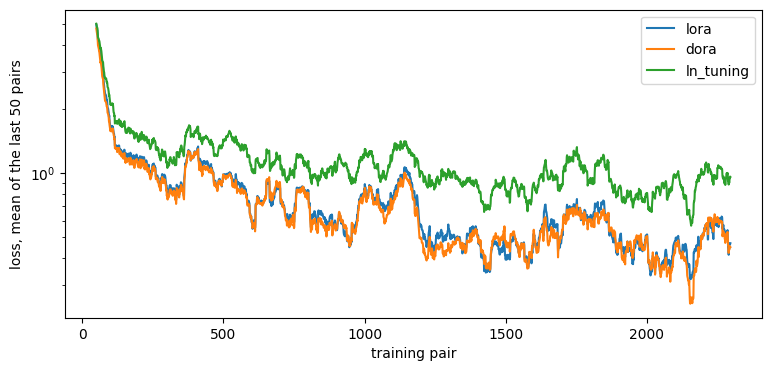

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
for m in finished():
    losses = pd.Series(json.loads((RUNS / f"{m}.json").read_text())["losses"])
    if len(losses):
        ax.plot(losses.rolling(50).mean(), label=m)
ax.set_xlabel("training pair")
ax.set_ylabel("loss, mean of the last 50 pairs")
ax.set_yscale("log")
ax.legend()
plt.show()

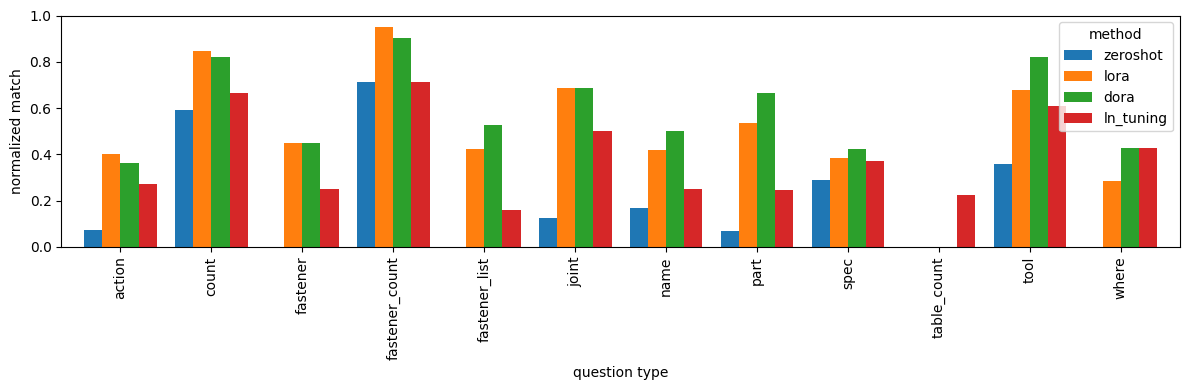

In [20]:
per_type = pd.DataFrame({m: load_run(m).groupby("qtype").normalized.mean() for m in finished()})
ax = per_type.plot.bar(figsize=(12, 4), width=0.8)
ax.set_ylabel("normalized match")
ax.set_xlabel("question type")
ax.legend(title="method")
plt.tight_layout()
plt.show()

### 2. Choosing a method

Rank the three fine-tuning methods by normalized match and by cost: trainable parameters, peak memory, training time and checkpoint size. Which would you deploy, and why? You trained each method once, so say whether the gap between the two closest methods could come from the seed alone, and what you would run to find out.

**Answer:**

Ranking the three fine-tuned models by accuracy puts DoRA in first place at 0.564 normalized match, followed by LoRA at 0.526, and ln_tuning last at 0.392. When you rank them by cost, the order flips and stays identical across every resource metric: ln_tuning is the cheapest by far, LoRA sits in the middle, and DoRA is the most expensive. For deployment, I would pick DoRA because it gives the best accuracy (+0.038 normalized and +0.044 exact over LoRA) while keeping essentially the same deployment footprint (11.8 MB vs. 11.1 MB, and both can be merged into the base weights for zero inference overhead), making the extra 8.3 minutes and 0.42 GiB a minor one-time training cost, while ln_tuning gives up too much accuracy to be practical.

That said, because we only trained each method once, the 0.038 gap between DoRA and LoRA is small enough that random seed noise from weight initialization, dropout, or epoch shuffling could plausibly explain it. To find out for sure, I would re-run both LoRA and DoRA across three to five different random seeds (varying both torch.manual_seed and the data-shuffling random_state) and compare their mean and standard deviation.

### 3. Failure cases

Take your best method and pick five test pairs it gets wrong under the normalized match. Show the image, the question, the reference and the prediction for each in the cell below. For each one, say whether the reference, the normalization or the model is at fault.

**Answer:**

Looking at five sampled DoRA failures shows a mix of model mistakes and strict grading edge cases. In Case 1 (page 174, "Which bearing race number is pressed in?"), the model predicts '#30203 taper roller bearing' instead of '#30203', which is on the model for being overly verbose rather than stopping at the bearing number. In Case 3 (page 177, "How should J6 housing rotation feel after setting tension?"), the model predicts 'no play 6 housing rotation, also it rotates smoothly' instead of 'no play, rotates smoothly', another model fault, since it misread "J6" as "6" and carried over extra words. In Case 5 (page 121, "What tool or material does this step call for?"), the model predicts 'brown and blue pairs' against 'solder', which is primarily a model error, though the reference 'solder' is also questionable because the page's note mentions soldering happens in the next step while the photo shows trimming wires.

The remaining two cases come down to the reference and normalization rather than real comprehension errors. In Case 2 (page 227, "How many tape marks identify the J5 motor/cable wires?"), the model answers '5' while the reference is '5 marks'. I feel that the reference is at fault here for inconsistently attaching the unit noun "marks" to a "How many..." count question. In Case 4 (page 125, "What length should the 8mm shaft be?"), the model answers '50mm long' directly from the bullet text "8mm shaft should be 50mm long." against the reference '50mm'; here normalization is at fault because '50mm long' is semantically identical and natural, yet strict word-for-word matching penalizes the adjective "long".

Best fine-tuned method: dora (normalized=0.564)


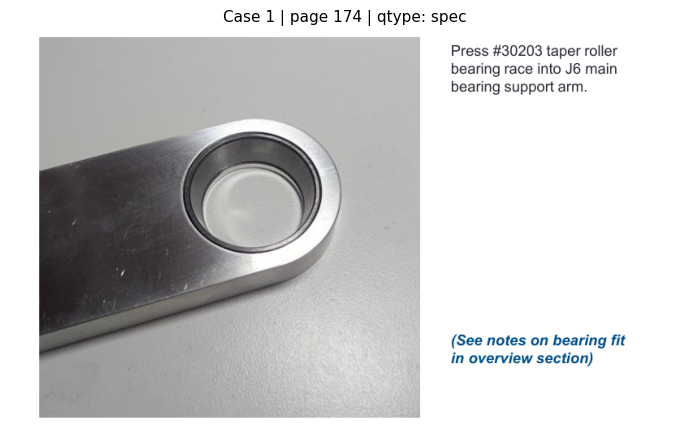

Case 1 (id=s238-01170, qtype=spec, page=174)
  Question  : Which bearing race number is pressed in?
  Reference : '#30203'  [norm: '#30203']
  Prediction: '#30203 taper roller bearing'  [norm: '#30203 taper roller bearing']
----------------------------------------------------------------------


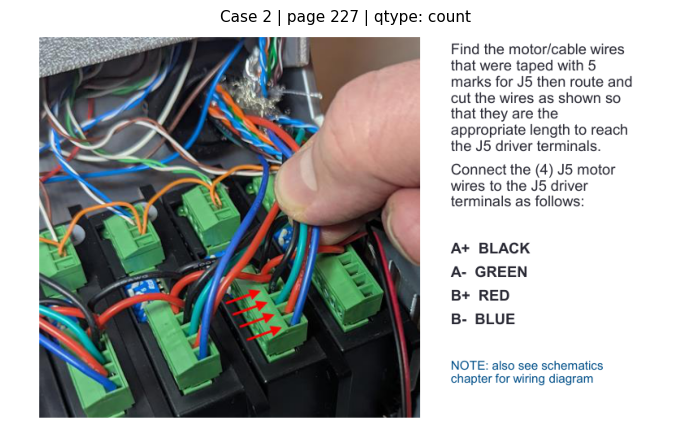

Case 2 (id=s341-00725, qtype=count, page=227)
  Question  : How many tape marks identify the J5 motor/cable wires?
  Reference : '5 marks'  [norm: '5 marks']
  Prediction: '5'  [norm: '5']
----------------------------------------------------------------------


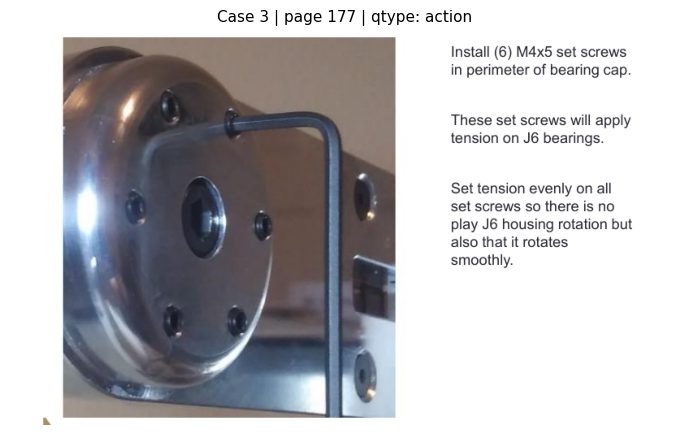

Case 3 (id=s245-00395, qtype=action, page=177)
  Question  : How should J6 housing rotation feel after setting tension?
  Reference : 'no play, rotates smoothly'  [norm: 'no play rotates smoothly']
  Prediction: 'no play 6 housing rotation, also it rotates smoothly'  [norm: 'no play 6 housing rotation also it rotates smoothly']
----------------------------------------------------------------------


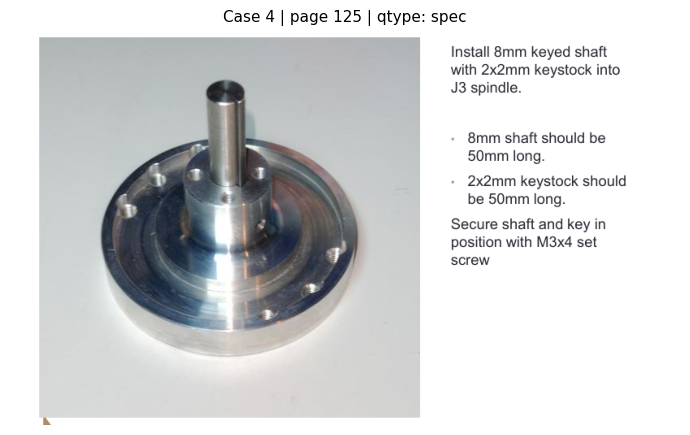

Case 4 (id=s143-01111, qtype=spec, page=125)
  Question  : What length should the 8mm shaft be?
  Reference : '50mm'  [norm: '50mm']
  Prediction: '50mm long'  [norm: '50mm long']
----------------------------------------------------------------------


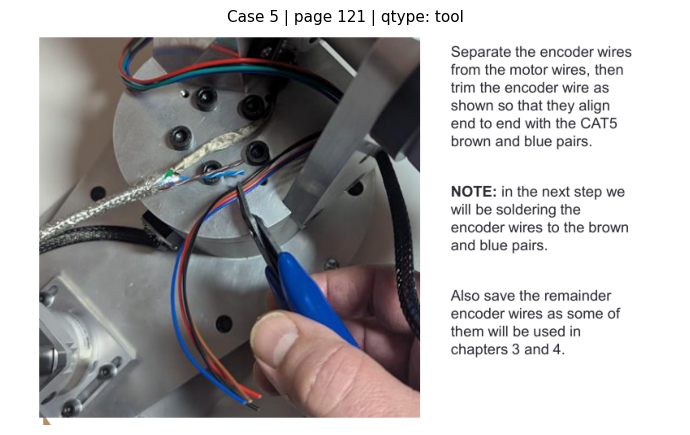

Case 5 (id=s135-00080, qtype=tool, page=121)
  Question  : What tool or material does this step call for?
  Reference : 'solder'  [norm: 'solder']
  Prediction: 'brown and blue pairs'  [norm: 'brown and blue pairs']
----------------------------------------------------------------------


In [21]:
# Five failure cases of your best method
summary = compare().drop(index="zeroshot", errors="ignore")
best_method = summary["normalized"].idxmax()
print(f"Best fine-tuned method: {best_method} (normalized={summary.loc[best_method, 'normalized']:.3f})")

best_res = load_run(best_method)
failed = (
    best_res[~best_res["normalized"]]
    .merge(test_df[["id", "page", "bbox"]], on="id", how="left")
)

sample_failures = failed.sample(min(5, len(failed)), random_state=0)

for i, row in enumerate(sample_failures.itertuples(), start=1):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.imshow(render(row.page, row.bbox))
    ax.axis("off")
    ax.set_title(f"Case {i} | page {row.page} | qtype: {row.qtype}", fontsize=11)
    plt.tight_layout()
    plt.show()

    print(f"Case {i} (id={row.id}, qtype={row.qtype}, page={row.page})")
    print(f"  Question  : {row.question}")
    print(f"  Reference : {row.answer!r}  [norm: {normalize(row.answer)!r}]")
    print(f"  Prediction: {row.pred!r}  [norm: {normalize(row.pred)!r}]")
    print("-" * 70)

### 4. Leakage

Every step image shows its own printed instruction, and the test pairs come from page blocks that training never sees, with neighboring pages and shared photos removed.

1. Explain why a random split of the 1,493 pairs would have given a higher test score than this split, and why that score would mislead you.
2. Name one way information about the test pairs can still reach training under this split, and describe how you would measure its effect on the score.

**Answer:** 

A random split of all 1,493 pairs would produce a noticeably higher (and misleading) test score because consecutive assembly steps frequently reuse near-identical bench photos and describe adjacent actions on the same sub-assembly, and multiple questions can come from the same page. Under a random split, the training set would contain near-duplicate images and neighboring context for a large portion of the test set, allowing the model to memorize specific photos, page layouts, and part facts rather than learning how to read unseen manual pages.

Even with the block-by-page split and adjacent/shared-photo removal, test information can still reach training through recurring manual content and shared doc knowledge. The AR4 manual repeats very similar sub-procedures, phrasing templates, and hardware across non-adjacent blocks (such as wiring, motor, and bearing steps across joints J1-J6), and the doc parts-list pages (pages 16-50) catalog the same parts and fastener specs tested in held-out step blocks while also contributing pairs to both train and test. To measure how much this affects the score, you could flag training-to-test overlap by checking for shared doc pages, high image-embedding similarity, or identical answers/near-duplicate phrasing and either compare test accuracy on high-overlap vs. novel test questions or retrain after removing the overlapping training pairs and measure how much the test score drops.

## Submitting

Commit this file with every cell output saved, together with the CSV and JSON files in `runs/`, under `assignments/assignment-3` in your clone of the class repository. Leave out the checkpoint folders in `runs/`. Submit the GitHub URL of that folder, not the repository root.